# Gráficos — Densest k-Subgraph

Este notebook reproduz os três gráficos de barras da apresentação:
1. Heurística × ótimo do MIP;
2. Limites do relaxado × ótimo;
3. Tempo de execução.

**Origem dos dados:** valores transcritos da tabela e dos gráficos do PDF da apresentação. Os tempos estão registrados como aparecem no slide; para o terceiro gráfico, foram convertidos para segundos para comparar as escalas corretamente. Execute as células em ordem para reproduzir os gráficos.

In [5]:
%pip install pandas matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

instancias = ['EX', 'P1', 'P2', 'M1', 'M2', 'G1', 'G2']

dados = pd.DataFrame({
    'Instancia': instancias,
    'n': [8, 15, 20, 50, 80, 150, 300],
    'k': [4, 5, 6, 10, 15, 25, 40],
    'Heuristica': [4, 10, 13, 17, 27, 47, 77],
    'MIP_otimo': [4, 10, 13, 17, 27, 47, 77],
    'Relaxado': [4.67, 17.92, 21.60, 19.40, 29.44, 49.50, 79.60],
    'Relaxado_reforco': [4.67, 10.00, 15.00, 19.40, 29.44, 49.50, 79.60],
})

tempos = pd.DataFrame({
    'Instancia': instancias,
    'Heuristica_ms': [0.04, 0.11, 0.06, 0.12, 0.24, 0.74, 2.28],
    'MIP_s': [1.68, 0.41, 0.51, 0.05, 1.33, 1.57, 4.05],
})

tempos['Heuristica_s'] = tempos['Heuristica_ms'] / 1000

display(dados)
display(tempos)

,Instancia,n,k,Heuristica,MIP_otimo,Relaxado,Relaxado_reforco
0,EX,8,4,4,4,4.67,4.67
1,P1,15,5,10,10,17.92,10.00
2,P2,20,6,13,13,21.60,15.00
3,M1,50,10,17,17,19.40,19.40
4,M2,80,15,27,27,29.44,29.44
5,G1,150,25,47,47,49.50,49.50
6,G2,300,40,77,77,79.60,79.60


,Instancia,Heuristica_ms,MIP_s,Heuristica_s
0,EX,0.04,1.68,0.00004
1,P1,0.11,0.41,0.00011
2,P2,0.06,0.51,0.00006
3,M1,0.12,0.05,0.00012
4,M2,0.24,1.33,0.00024
5,G1,0.74,1.57,0.00074
6,G2,2.28,4.05,0.00228


## 1. Heurística × ótimo do MIP

Compara o número de arestas encontrado pela heurística com o ótimo inteiro informado pelo solver.

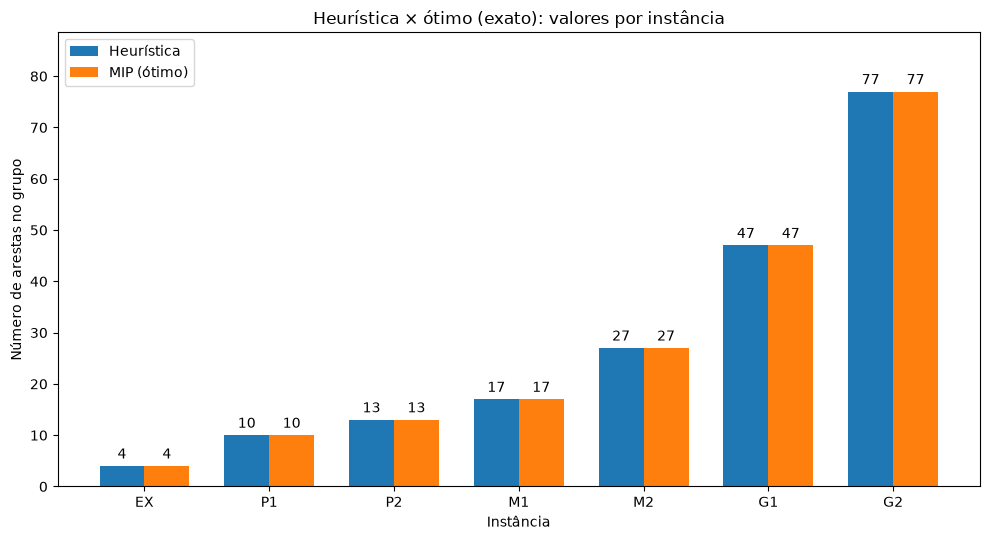

In [7]:
x = np.arange(len(dados))
largura = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.bar(x - largura/2, dados['Heuristica'], largura, label='Heurística')
b2 = ax.bar(x + largura/2, dados['MIP_otimo'], largura, label='MIP (ótimo)')

ax.set_title('Heurística × ótimo (exato): valores por instância')
ax.set_xlabel('Instância')
ax.set_ylabel('Número de arestas no grupo')
ax.set_xticks(x, dados['Instancia'])
ax.legend()
ax.bar_label(b1, padding=3, fmt='%.0f')
ax.bar_label(b2, padding=3, fmt='%.0f')
ax.set_ylim(0, max(dados['MIP_otimo']) * 1.15)
fig.tight_layout()
plt.show()

## 2. Limites do relaxado × ótimo

O ótimo inteiro é comparado ao limite superior do relaxado sem reforço e com reforço.

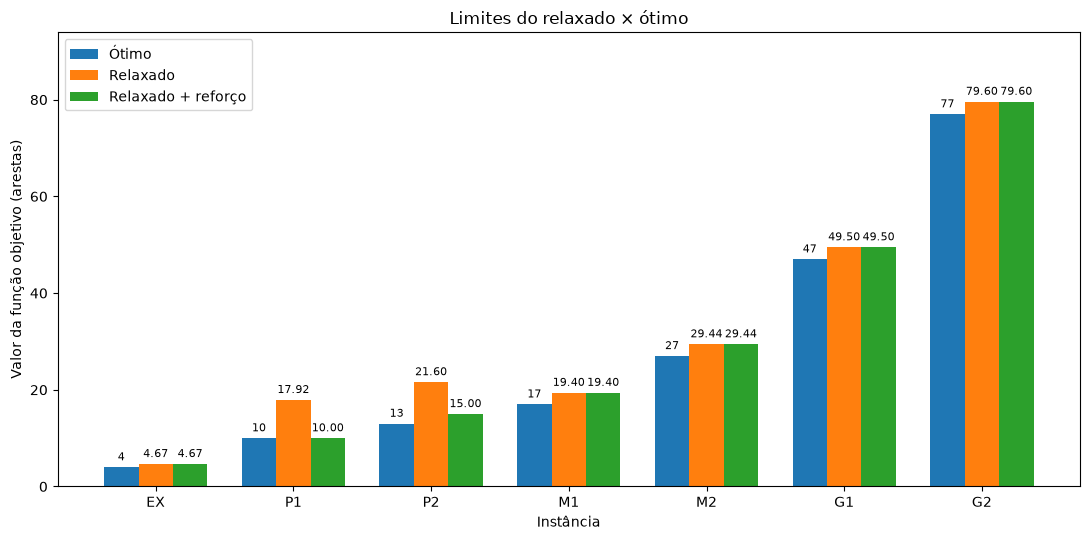

In [8]:
x = np.arange(len(dados))
largura = 0.25

fig, ax = plt.subplots(figsize=(11, 5.5))
b1 = ax.bar(x - largura, dados['MIP_otimo'], largura, label='Ótimo')
b2 = ax.bar(x, dados['Relaxado'], largura, label='Relaxado')
b3 = ax.bar(x + largura, dados['Relaxado_reforco'], largura, label='Relaxado + reforço')

ax.set_title('Limites do relaxado × ótimo')
ax.set_xlabel('Instância')
ax.set_ylabel('Valor da função objetivo (arestas)')
ax.set_xticks(x, dados['Instancia'])
ax.legend()
ax.bar_label(b1, padding=3, fmt='%.0f', fontsize=8)
ax.bar_label(b2, padding=3, fmt='%.2f', fontsize=8)
ax.bar_label(b3, padding=3, fmt='%.2f', fontsize=8)
ax.set_ylim(0, max(dados['Relaxado']) * 1.18)
fig.tight_layout()
plt.show()

## 3. Tempo de execução

Os tempos da heurística foram exibidos originalmente em milissegundos e os do MIP em segundos. Aqui, ambos são convertidos para segundos e o eixo vertical usa escala logarítmica, porque os tempos diferem por várias ordens de magnitude.

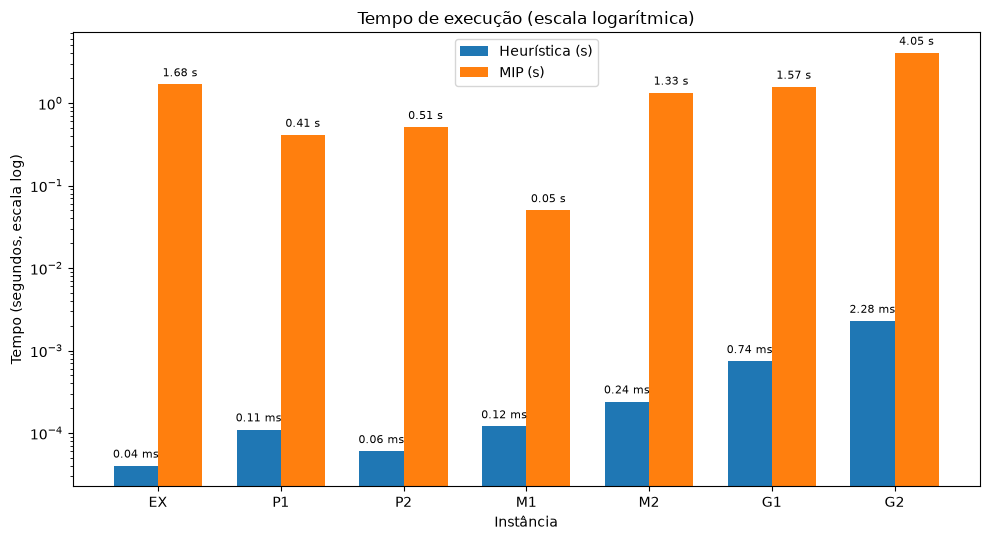

In [9]:
x = np.arange(len(tempos))
largura = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.bar(x - largura/2, tempos['Heuristica_s'], largura, label='Heurística (s)')
b2 = ax.bar(x + largura/2, tempos['MIP_s'], largura, label='MIP (s)')

ax.set_title('Tempo de execução (escala logarítmica)')
ax.set_xlabel('Instância')
ax.set_ylabel('Tempo (segundos, escala log)')
ax.set_xticks(x, tempos['Instancia'])
ax.set_yscale('log')
ax.legend()

rotulos_heuristica = [f'{v:g} ms' for v in tempos['Heuristica_ms']]
rotulos_mip = [f'{v:.2f} s' for v in tempos['MIP_s']]
for barra, rotulo in zip(b1, rotulos_heuristica):
    ax.annotate(rotulo, (barra.get_x() + barra.get_width()/2, barra.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8)
for barra, rotulo in zip(b2, rotulos_mip):
    ax.annotate(rotulo, (barra.get_x() + barra.get_width()/2, barra.get_height()),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8)

fig.tight_layout()
plt.show()

## Observações sobre a reprodução

- Os gráficos reproduzem os valores que aparecem nos slides, não uma nova execução do solver.